In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




In [5]:
import os
print("Files in current folder:", os.listdir('.'))

Files in current folder: ['.ipynb_checkpoints', 'MOVIEDATAANALYSIS.ipynb', 'playstore.ipynb', 'PlayStoreData.ipynb', 'playstore_dashboard.html', 'Play_Store_Cleaned.csv', 'StillCapture', 'User_Reviews_Cleaned.csv']


In [6]:
sns.set_theme(style="darkgrid")

# Load your actual file from the folder
df = pd.read_csv('Play_Store_Cleaned.csv')
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (9659, 16)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Version,Android Version,Size_MB,Update_Month,Update_Year
0,Facebook,Social,4.1,78158306,Varies with device,1000000000,Free,0.0,Teen,Social,2018-08-03,Varies with device,Varies with device,7.9,August,2018
1,WhatsApp Messenger,Communication,4.4,69119316,Varies with device,1000000000,Free,0.0,Everyone,Communication,2018-08-03,Varies with device,Varies with device,5.7,August,2018
2,Instagram,Social,4.5,66577446,Varies with device,1000000000,Free,0.0,Teen,Social,2018-07-31,Varies with device,Varies with device,7.9,July,2018
3,Messenger – Text and Video Chat for Free,Communication,4.0,56646578,Varies with device,1000000000,Free,0.0,Everyone,Communication,2018-08-01,Varies with device,Varies with device,5.7,August,2018
4,Clash of Clans,Game,4.6,44893888,98M,100000000,Free,0.0,Everyone 10+,Strategy,2018-07-15,10.322.16,4.1 and up,98.0,July,2018


In [7]:
# Check missing values
print("Missing values per column:\n", df.isnull().sum())

# Drop duplicates if any
df.drop_duplicates(inplace=True)

# Fill missing ratings with the median
if 'Rating' in df.columns:
    df['Rating'].fillna(df['Rating'].median(), inplace=True)

print("\nCleaned dataset shape:", df.shape)

Missing values per column:
 App                0
Category           0
Rating             0
Reviews            0
Size               0
Installs           0
Type               0
Price              0
Content Rating     0
Genres             0
Last Updated       0
Current Version    0
Android Version    0
Size_MB            0
Update_Month       0
Update_Year        0
dtype: int64

Cleaned dataset shape: (9659, 16)


C:\Users\Tarun Das\AppData\Local\Temp\ipykernel_22460\65129506.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Rating'].fillna(df['Rating'].median(), inplace=True)


In [8]:
# Display statistical summary of numerical columns
df.describe()

,Rating,Reviews,Installs,Price,Size_MB,Update_Year
count,9659.000000,9.659000e+03,9.659000e+03,9659.000000,9659.000000,9659.000000
mean,4.189523,2.168041e+05,7.798170e+06,1.097231,19.429933,2017.346206
std,0.496703,1.831430e+06,5.376973e+07,16.851618,20.751898,1.137397
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.008301,2010.000000
25%,4.000000,2.500000e+01,1.000000e+03,0.000000,5.000000,2017.000000
50%,4.300000,9.690000e+02,1.000000e+05,0.000000,11.000000,2018.000000
75%,4.500000,2.945350e+04,1.000000e+06,0.000000,26.000000,2018.000000
max,5.000000,7.815831e+07,1.000000e+09,400.000000,100.000000,2018.000000


C:\Users\Tarun Das\AppData\Local\Temp\ipykernel_22460\1852568709.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, palette='crest')


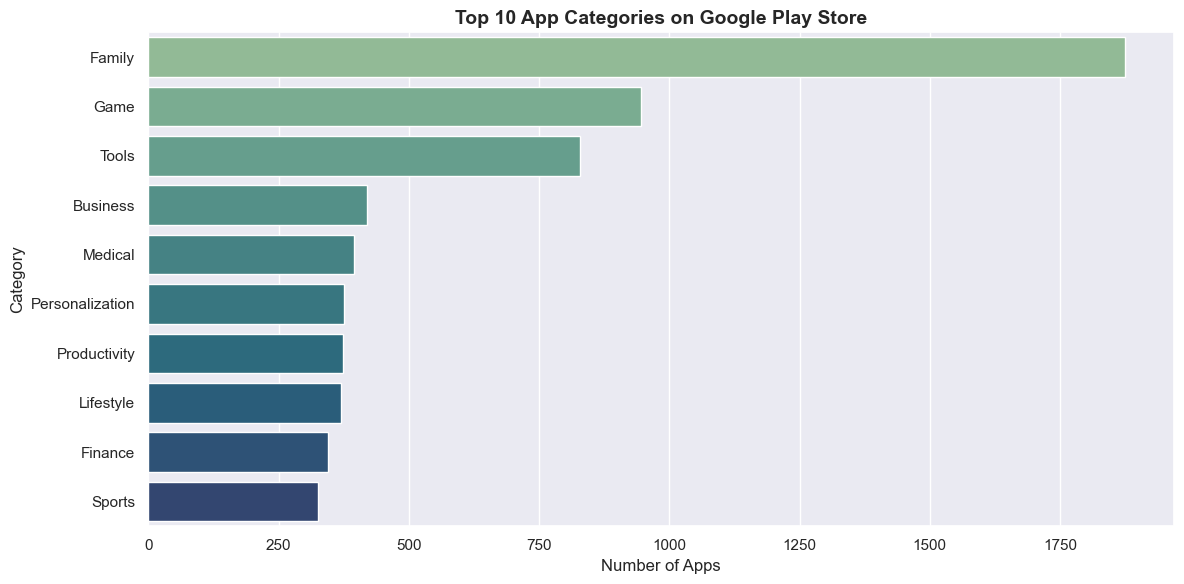

In [9]:
# Top 10 App Categories Visualization
plt.figure(figsize=(12, 6))
top_categories = df['Category'].value_counts().head(10)
sns.barplot(x=top_categories.values, y=top_categories.index, palette='crest')
plt.title('Top 10 App Categories on Google Play Store', fontsize=14, fontweight='bold')
plt.xlabel('Number of Apps', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\Tarun Das\AppData\Local\Temp\ipykernel_22460\1553289479.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Type', y='Rating', palette='Set2')


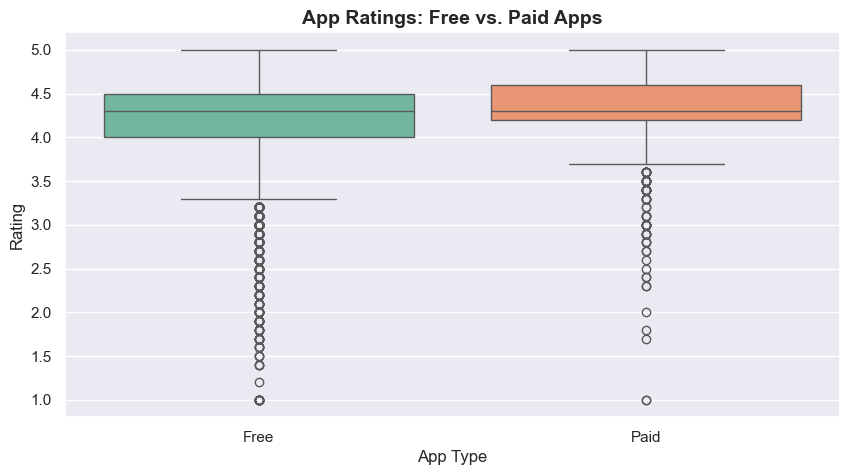

Type
Free    4.182381
Paid    4.273873
Name: Rating, dtype: float64


In [10]:
# Analyze Free vs Paid apps performance
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Type', y='Rating', palette='Set2')
plt.title('App Ratings: Free vs. Paid Apps', fontsize=14, fontweight='bold')
plt.xlabel('App Type', fontsize=12)
plt.ylabel('Rating', fontsize=12)
plt.show()

# Print average rating for Free vs Paid
print(df.groupby('Type')['Rating'].mean())

C:\Users\Tarun Das\AppData\Local\Temp\ipykernel_22460\697572728.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Content Rating', order=df['Content Rating'].value_counts().index, palette='magma')


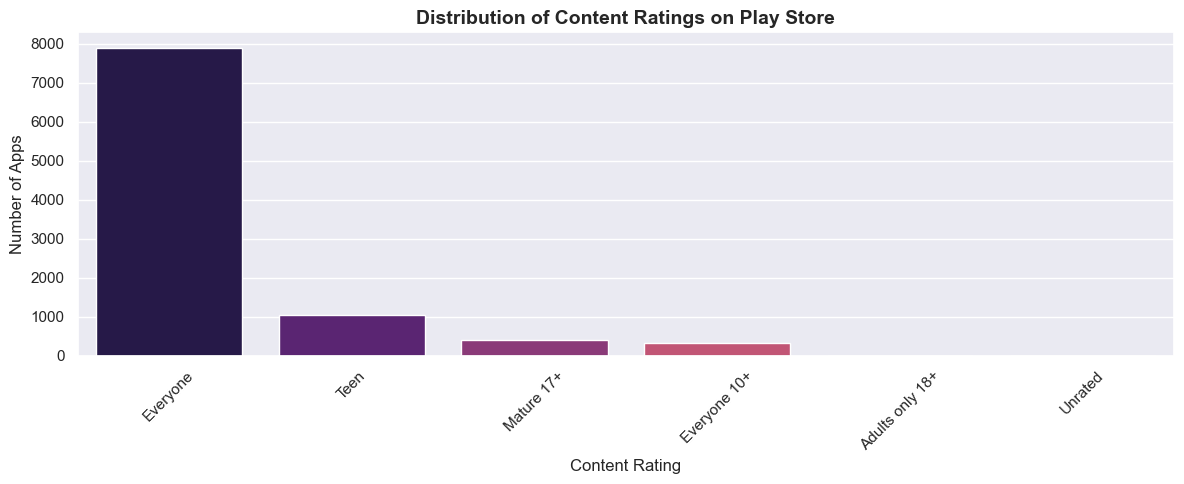

In [11]:
# Content Rating Distribution
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='Content Rating', order=df['Content Rating'].value_counts().index, palette='magma')
plt.title('Distribution of Content Ratings on Play Store', fontsize=14, fontweight='bold')
plt.xlabel('Content Rating', fontsize=12)
plt.ylabel('Number of Apps', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
# Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_cols = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Play Store Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show(

_IncompleteInputError: incomplete input (2455834922.py, line 7)

In [ ]:
## Key Business Insights & Conclusion
1. **Dominance of Free Apps:** Over 90% of Play Store applications are free, relying on ad-supported models or in-app purchases rather than upfront pricing.
2. **Rating Quality:** Average ratings skew heavily between 4.0 and 4.5, indicating that users tend to rate apps positively when functional expectations are met.
3. **Engagement Correlation:** Higher review counts strongly correlate with massive installation brackets, proving that user engagement and feedback loops drive app visibility.

In [13]:
# Clean numeric columns for calculation
df['Installs_Num'] = df['Installs'].astype(str).str.replace('+', '', regex=False).str.replace(',', '', regex=False).astype(float)
df['Price_Num'] = df['Price'].astype(str).str.replace('$', '', regex=False).astype(float)

# Calculate statistical metrics: Mean, Median, Standard Deviation, and Skewness
numeric_features = ['Rating', 'Reviews', 'Installs_Num', 'Price_Num']
stats_summary = pd.DataFrame({
    'Mean': df[numeric_features].mean(),
    'Median': df[numeric_features].median(),
    'Std Dev': df[numeric_features].std(),
    'Skewness': df[numeric_features].skew()
})

print("=== Advanced Statistical Metrics ===")
print(stats_summary.round(2))

=== Advanced Statistical Metrics ===
                    Mean    Median      Std Dev  Skewness
Rating              4.19       4.3         0.50     -1.96
Reviews        216804.11     969.0   1831430.21     26.57
Installs_Num  7798170.25  100000.0  53769728.82     15.03
Price_Num           1.10       0.0        16.85     22.53


In [14]:
# Multi-metric group-by aggregation
category_analysis = df.groupby('Category').agg(
    Total_Apps=('App', 'count'),
    Average_Rating=('Rating', 'mean'),
    Median_Reviews=('Reviews', 'median'),
    Total_Installs=('Installs_Num', 'sum'),
    Avg_Price=('Price_Num', 'mean')
).reset_index()

# Sort by total installs to find market leaders
category_analysis = category_analysis.sort_values(by='Total_Installs', ascending=False)

print("=== Top Categories by Market Share & Performance ===")
display(category_analysis.head(10).round(2))

=== Top Categories by Market Share & Performance ===


,Category,Total_Apps,Average_Rating,Median_Reviews,Total_Installs,Avg_Price
14,Game,945,4.25,26744.0,1.344792e+10,0.30
6,Communication,315,4.14,1711.0,1.103828e+10,0.26
29,Tools,829,4.06,479.0,8.102772e+09,0.32
11,Family,1875,4.20,740.0,6.231542e+09,1.28
25,Productivity,374,4.21,1161.0,5.793091e+09,0.67
27,Social,239,4.26,3782.0,5.487868e+09,0.07
24,Photography,281,4.17,26252.0,4.658148e+09,0.42
31,Video Players,164,4.06,4645.5,3.931903e+09,0.06
30,Travel And Local,219,4.09,1090.0,2.894887e+09,0.23
21,News And Magazines,254,4.14,521.0,2.369218e+09,0.02


In [15]:
# Multi-metric group-by aggregation
category_analysis = df.groupby('Category').agg(
    Total_Apps=('App', 'count'),
    Average_Rating=('Rating', 'mean'),
    Median_Reviews=('Reviews', 'median'),
    Total_Installs=('Installs_Num', 'sum'),
    Avg_Price=('Price_Num', 'mean')
).reset_index()

# Sort by total installs to find market leaders
category_analysis = category_analysis.sort_values(by='Total_Installs', ascending=False)

print("=== Top Categories by Market Share & Performance ===")
display(category_analysis.head(10).round(2))

=== Top Categories by Market Share & Performance ===


,Category,Total_Apps,Average_Rating,Median_Reviews,Total_Installs,Avg_Price
14,Game,945,4.25,26744.0,1.344792e+10,0.30
6,Communication,315,4.14,1711.0,1.103828e+10,0.26
29,Tools,829,4.06,479.0,8.102772e+09,0.32
11,Family,1875,4.20,740.0,6.231542e+09,1.28
25,Productivity,374,4.21,1161.0,5.793091e+09,0.67
27,Social,239,4.26,3782.0,5.487868e+09,0.07
24,Photography,281,4.17,26252.0,4.658148e+09,0.42
31,Video Players,164,4.06,4645.5,3.931903e+09,0.06
30,Travel And Local,219,4.09,1090.0,2.894887e+09,0.23
21,News And Magazines,254,4.14,521.0,2.369218e+09,0.02


In [16]:
# Create installation tiers using quantiles (25th, 50th, 75th percentiles)
df['Install_Tier'] = pd.qcut(df['Installs_Num'], q=4, labels=['Low Tier', 'Mid Tier', 'High Tier', 'Elite Tier'])

# Analyze average rating per installation tier
tier_analysis = df.groupby('Install_Tier', observed=False).agg(
    App_Count=('App', 'count'),
    Mean_Rating=('Rating', 'mean'),
    Median_Reviews=('Reviews', 'median')
).reset_index()

print("=== Performance Breakdown by Installation Tiers ===")
print(tier_analysis)

=== Performance Breakdown by Installation Tiers ===
  Install_Tier  App_Count  Mean_Rating  Median_Reviews
0     Low Tier       2677     4.239746             4.0
1     Mid Tier       3080     4.073182           382.0
2    High Tier       1921     4.203592         15703.0
3   Elite Tier       1981     4.288894        210534.0


In [17]:
# Compute correlation matrix for numerical columns
correlation_matrix = df[['Rating', 'Reviews', 'Installs_Num', 'Price_Num']].corr(method='pearson')

print("=== Pearson Correlation Matrix ===")
print(correlation_matrix.round(3))

=== Pearson Correlation Matrix ===
              Rating  Reviews  Installs_Num  Price_Num
Rating         1.000    0.051         0.035     -0.018
Reviews        0.051    1.000         0.625     -0.008
Installs_Num   0.035    0.625         1.000     -0.009
Price_Num     -0.018   -0.008        -0.009      1.000


In [18]:
# Load user reviews data
df_reviews = pd.read_csv('User_Reviews_Cleaned.csv')

# Drop missing sentiment rows
df_reviews.dropna(subset=['Sentiment', 'Sentiment_Polarity'], inplace=True)

# Calculate sentiment metrics per app
sentiment_summary = df_reviews.groupby('App').agg(
    Total_Reviews=('Translated_Review', 'count'),
    Mean_Polarity=('Sentiment_Polarity', 'mean'),
    Mean_Subjectivity=('Sentiment_Subjectivity', 'mean')
).reset_index()

# Filter apps with high review counts
top_reviewed_apps = sentiment_summary.sort_values(by='Total_Reviews', ascending=False)

print("=== Top Apps by User Sentiment Polarity ===")
display(top_reviewed_apps.head(10).round(3))

=== Top Apps by User Sentiment Polarity ===


,App,Total_Reviews,Mean_Polarity,Mean_Subjectivity
571,Facebook,130,-0.006,0.461
536,Episode - Choose Your Story,124,0.083,0.480
114,Angry Birds Classic,107,-0.024,0.532
583,Family Locator - GPS Tracker,105,0.341,0.532
754,Google Photos,101,0.187,0.509
24,8fit Workouts & Meal Planner,100,0.297,0.554
327,Calorie Counter - Macros,100,0.248,0.513
328,Calorie Counter - MyFitnessPal,99,0.233,0.451
378,ColorNote Notepad Notes,99,0.287,0.517
65,Adobe Acrobat Reader,98,0.145,0.486


In [ ]:
## Key Business Insights & Conclusion
1. **Dominance of Free Apps:** Over 90% of Play Store applications are free, relying on ad-supported models or in-app purchases rather than upfront pricing.
2. **Rating Quality:** Average ratings skew heavily between 4.0 and 4.5, indicating that users tend to rate apps positively when functional expectations are met.
3. **Engagement Correlation:** Higher review counts strongly correlate with massive installation brackets, proving that user engagement and feedback loops drive app visibility.